# Companion notebook: Cryptography Decoded: Classical Encryption Methods

© 2001–2026 Gerald Teschl (http://www.mat.univie.ac.at/~gerald/) and Susanne Teschl (http://staff.technikum-wien.at/~teschl/)

This [Python](https://python.org) notebook is intended as a supplement to our book "[Cryptography Decoded](https://www.mat.univie.ac.at/~gerald/ftp/book-cry/)." Additional explanations can also be found there.

## Classical encryption methods

### The Caesar cipher

Encryption:

In [1]:
def caesar(x: str, e: int) -> str:
    "Rotate all letters in `x` by `e` places."
    e = e % 26
    y = ""
    for c in x:
        if c.isupper():
            y += chr((ord(c) + e - 65) % 26 + 65)
        elif c.islower():
            y += chr((ord(c) + e - 97) % 26 + 97)
        else:
            y += c
    return y


caesar("THESEGAULSARECRAZY", 3)

'WKHVHJDXOVDUHFUDCB'

Decryption:

In [2]:
caesar(_, -3)

'THESEGAULSARECRAZY'

Counting letter frequencies:

In [3]:
def letter_freq(x: str) -> list[float]:
    "Determine the letter frequencies for the characters of a string `x`."
    lf = [0] * 26
    x = x.upper()
    for c in x:
        o = ord(c) - 65
        if 0 <= o <= 25:
            lf[o] += 1
    for i in range(26):
        lf[i] /= len(x)
    return lf

Estimating the shift from the most frequent letter:

In [4]:
ciphertext = "YMNXYJCYNXSTQTSLJWXJHWJY"

lf = letter_freq(ciphertext)
mfl = lf.index(max(lf))
e = (mfl - 4) % 26
print(chr(65 + mfl), e)
caesar(ciphertext, -e)

J 5


'THISTEXTISNOLONGERSECRET'

Here's an alternative version using XOR for encryption:

In [5]:
def xor1(m: bytes, key: int) -> bytes:
    """En-/decrypt a message by xoring with a key byte."""
    c = bytearray(b"")
    for x in m:
        c.append(x ^ key)
    return bytes(c)

plaintext = b"Top Secret!"
print([c for c in plaintext])
[ c for c in xor1(plaintext, 127) ]

[84, 111, 112, 32, 83, 101, 99, 114, 101, 116, 33]


[43, 16, 15, 95, 44, 26, 28, 13, 26, 11, 94]

### Letter frequency index

Letter frequencies for English and German:

In [6]:
lf_en = [ 0.0804, 0.0148, 0.0334, 0.0382, 0.1249, 0.0240, 0.0187, 0.0505, 0.0757, 0.0016, 0.0054, 0.0407, 0.0251,
    0.0723, 0.0764, 0.0214, 0.0012, 0.0628, 0.0651, 0.0928, 0.0273, 0.0105, 0.0168, 0.0023, 0.0166, 0.0009 ]

lf_de = [ 0.0651, 0.0189, 0.0306, 0.0508, 0.174, 0.0166, 0.0301, 0.0476, 0.0755, 0.0027, 0.0121, 0.0344, 0.0253,
    0.0978, 0.0251, 0.0079, 0.0002, 0.07, 0.0727, 0.0615, 0.0435, 0.0067, 0.0189, 0.0003, 0.0004, 0.0113 ]

Calculating the letter frequency index of a text:

In [7]:
def lf_index(x: str | list[int]) -> int:
    "Compute the letter frequency index of a given string or list of letter frequencies `x`."
    if type(x) is str:
        x = letter_freq(x)
    K = 0.0
    n = len(x)
    for i in x:
        K += i**2
    K = (n / (n - 1)) * (K - 1 / n)
    return K


lf_index(ciphertext)

0.07194444444444445

The letter frequency index for a German text,

In [8]:
round(lf_index(lf_de), 3)

0.039

an English text,

In [9]:
round(lf_index(lf_en), 3)

0.029

and a random text:

In [10]:
round(lf_index([1 / 26] * 26), 3)

0.0

Checking whether a text was encrypted with a monoalphabetic or polyalphabetic cipher:

In [11]:
ciphertextm = "WZDVEULOOLJDQGWKHVOLWKBWRYHVGLGJBUHDQGJLPEOHLQWKHZDEHDOOPLPVBZHUHWKHERURJRYHVDQGWKHPRPHUDWKVRXWJUDEHEHZDUHWKHMDEEHUZRFNPBVRQWKHMDZVWKDWELWHWKHFDWFKWKDWFDWFKEHZDUHWKHMXEMXEELUGDQGVKXQWKHIUXPLRXVEDQGHUVQDWFKKHWRRNKLVYRUSDOVZRUGLQKDQGORQJWLPHWKHPDQARPHIRHKHVRXJKWVRUHVWHGKHEBWKHWXPWXPWUHHDQGVWRRGDZKLOHLQWKRXJKWDQGDVLQXIILVKWKRXJKWKHVWRRGWKHMDEEHUZRFNZLWKHBHVRIIODPHFDPHZKLIIOLQJWKURXJKWKHWXOJHBZRRGDQGEXUEOHGDVLWFDPHRQHWZRRQHWZRDQGWKURXJKDQGWKURXJKWKHYRUSDOEODGHZHQWVQLFNHUVQDFNKHOHIWLWGHDGDQGZLWKLWVKHDGKHZHQWJDOXPSKLQJEDFNDQGKDVWWKRXVODLQWKHMDEEHUZRFNFRPHWRPBDUPVPBEHDPLVKERBRIUDEMRXVGDBFDOORRKFDOODBKHFKRUWOHGLQKLVMRBWZDVEULOOLJDQGWKHVOLWKBWRYHVGLGJBUHDQGJLPEOHLQWKHZDEHDOOPLPVBZHUHWKHERURJRYHVDQGWKHPRPHUDWKVRXWJUDEH"
ciphertextp = "VWRJPCTNLZXOYOVHVJZTEJYKFJPDFIUXMCPCNUXWXMNEZEHSPYASVOWWOIDJMHPTEKYSMZTOXFJPDCNUKVPXQMVIOESUOLKUCLDESVKLCGTYVXLMDEINCNVOYJFBESGJRNGESCTSZHPEJETRHNSVHRKQLEEHSVKLCGTYVXFMLUSSWCOCNUJVFYVHVWFFXKOLJPLYFEIJBLEEHYVHZZMHZJJZCRACJKZCFIEYOYONOEXHTXGTYVALYZODVTZPJEJFIRSVSFISDEGDYVPJEJEKLAEFOTIVSLYFSKFCOLYHZCSTYVHFLUSECNURGTYWFWZGSEJOLXVESGSKFCOEJEARPMPTWFTYHTVHVPSDZHFCRAPNCMVNVTQHLZEUESTOLXVESGTLCUPJYOFUOYODUISZPOCSZKQLXGOEVHHZQNVKKZLPDKYFZFIHRERESTOLXVESGVFIDLWDLRUSHPPTJEWNVGRJEONVJECVTETVDVRRLYFWZKVTEUHVRRSPYEEKULWWMGYWYRDATBOYOJAJKHSZWSCRWYEJEARPMPTWFTYNZOEKFAJLTMJDMMPCMZJVMZAOWIOMUQUJUOJNCLCFCSNCLCRMSPEHFIHWPFIEYWDUQYKNODMTICCWRLPDKYSDWKTYPHZGGSUZRRJTERERRTOBCVWYEJENRPPLNLDZADJYEIVHSPDOIFUZGGSRERESGMFDSCLVHJFIERTASV"

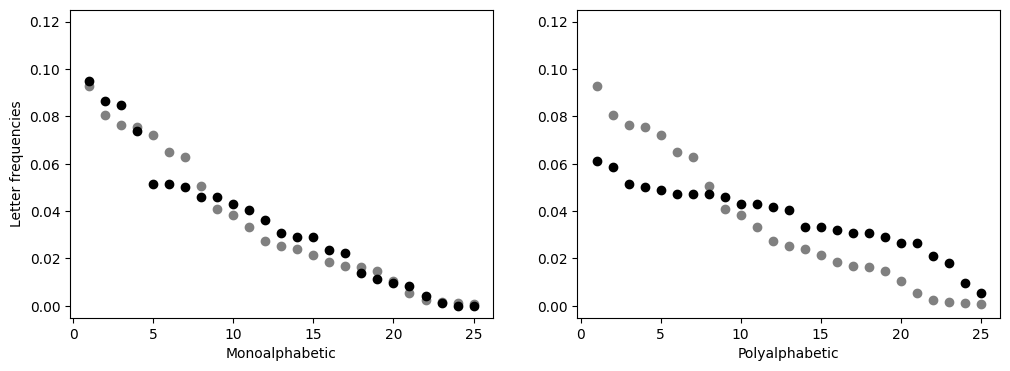

In [12]:
# requires "pip install matplotlib"
from matplotlib import pyplot as plt

slf_en = [ f for f in lf_en ]
slf_en.sort(reverse=True)
slf_ctp = letter_freq(ciphertextp)
slf_ctp.sort(reverse=True)
slf_ctm = letter_freq(ciphertextm)
slf_ctm.sort(reverse=True)

plt.figure(figsize=(12,4))
plt.subplot(1, 2, 1)
plt.ylim(-0.005, 0.125)
plt.scatter(range(1, 26), [slf_en[i] for i in range(1, 26)], color="grey")
plt.scatter(range(1, 26), [slf_ctm[i] for i in range(1, 26)], color="black")
plt.xlabel("Monoalphabetic")
plt.ylabel("Letter frequencies")
plt.subplot(1, 2, 2)
plt.ylim(-0.005, 0.125)
plt.scatter(range(1, 26), [slf_en[i] for i in range(1, 26)], color="grey")
plt.scatter(range(1, 26), [slf_ctp[i] for i in range(1, 26)], color="black")
plt.xlabel("Polyalphabetic")
#plt.ylabel("Letter frequencies")

#plt.savefig("letterfreq.pdf", format="pdf", bbox_inches='tight')
plt.show()

In [13]:
round(lf_index(ciphertextm), 3), round(lf_index(ciphertextp), 3)

(0.025, 0.007)

### Automated strategies

Finding the shift that minimizes the sum of squared differences between the [letter frequencies](https://de.wikipedia.org/wiki/Buchstabenhäufigkeit) and those expected for the language (cosine similarity):

In [14]:
def caesar_crack(y: str, lfx: list) -> int:
    "Find the most likely key of a Caesar ecrypted string `y` given the expected letter frequencies `lfx`."
    lf = letter_freq(y)
    dmin = 26
    emin = -1
    for e in range(26):
        d = 0
        for i in range(26):
            d += (lf[(i + e) % 26] - lfx[i]) ** 2
        if d < dmin:
            dmin = d
            emin = e
    return emin


ciphertext = "FTQMZEIQDFAFTQGXFUYMFQCGQEFUAZARXURQFTQGZUHQDEQMZPQHQDKFTUZSUERADFKFIA"
e = caesar_crack(ciphertext, lf_en)
print(f"e = {e}")
caesar(ciphertext, -e)

e = 12


'THEANSWERTOTHEULTIMATEQUESTIONOFLIFETHEUNIVERSEANDEVERYTHINGISFORTYTWO'

### The Vigenère cipher

Encryption

In [15]:
def vigenere(x: str, p: str, invert: bool = False) -> str:
    "Vigenere encrypt or decrypt a string `x` using the password `p`."
    key = []
    for c in p.upper():
        o = (ord(c) - 65) % 26
        if invert:
            key.append(-o)
        else:
            key.append(o)
    lk = len(key)
    y = ""
    for i, c in enumerate(x):
        if c.isupper():
            y += chr((ord(c) + key[i % lk] - 65) % 26 + 65)
        elif c.islower():
            y += chr((ord(c) + key[i % lk] - 97) % 26 + 97)
        else:
            y += c
    return y


vigenere("VERYSECRETTEXT", "VIGENERE")

'QMXCFITVZBZIKX'

Decryption

In [16]:
vigenere(_, "VIGENERE", invert=True)

'VERYSECRETTEXT'

Splitting a text into groups

In [17]:
def split_string(x: str, n: int) -> list[str]:
    "Split a string `x` into letters of distance `n`."
    return [x[i::n] for i in range(n)]


split_string("aAbBcCd", 2)

['abcd', 'ABC']

The average letter frequency index across the groups

In [18]:
def lf_index2(x, n):
    xx = split_string(x, n)
    lfi = 0
    for i in range(n):
        lfi += lf_index(xx[i])
    lfi = lfi / n
    return lfi


lf_index2("aabbcc", 2)

0.30666666666666664

Here's the ciphertext we want to decrypt:

In [19]:
# English example
ciphertext = "VWRJPCTNLZXOYOVHVJZTEJYKFJPDFIUXMCPCNUXWXMNEZEHSPYASVOWWOIDJMHPTEKYSMZTOXFJPDCNUKVPXQMVIOESUOLKUCLDESVKLCGTYVXLMDEINCNVOYJFBESGJRNGESCTSZHPEJETRHNSVHRKQLEEHSVKLCGTYVXFMLUSSWCOCNUJVFYVHVWFFXKOLJPLYFEIJBLEEHYVHZZMHZJJZCRACJKZCFIEYOYONOEXHTXGTYVALYZODVTZPJEJFIRSVSFISDEGDYVPJEJEKLAEFOTIVSLYFSKFCOLYHZCSTYVHFLUSECNURGTYWFWZGSEJOLXVESGSKFCOEJEARPMPTWFTYHTVHVPSDZHFCRAPNCMVNVTQHLZEUESTOLXVESGTLCUPJYOFUOYODUISZPOCSZKQLXGOEVHHZQNVKKZLPDKYFZFIHRERESTOLXVESGVFIDLWDLRUSHPPTJEWNVGRJEONVJECVTETVDVRRLYFWZKVTEUHVRRSPYEEKULWWMGYWYRDATBOYOJAJKHSZWSCRWYEJEARPMPTWFTYNZOEKFAJLTMJDMMPCMZJVMZAOWIOMUQUJUOJNCLCFCSNCLCRMSPEHFIHWPFIEYWDUQYKNODMTICCWRLPDKYSDWKTYPHZGGSUZRRJTERERRTOBCVWYEJENRPPLNLDZADJYEIVHSPDOIFUZGGSRERESGMFDSCLVHJFIERTASV"

Let's plot the results:

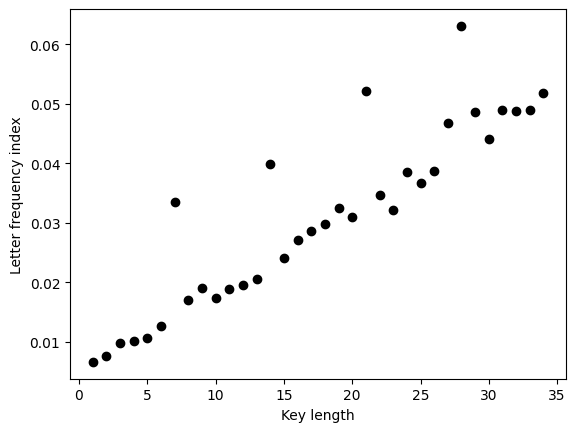

In [20]:
# requires "pip install matplotlib"
from matplotlib import pyplot as plt

n = 35
plt.scatter(range(1, n), [lf_index2(ciphertext, i) for i in range(1, n)], color="black")
plt.xlabel("Key length")
plt.ylabel("Letter frequency index")
#plt.savefig("carroll.pdf", format="pdf", bbox_inches='tight')
plt.show()

Since the peaks occur at 7, 14, 21, and 28, the key length is probably 11.

In [21]:
n = 7
c = split_string(ciphertext, n)
p = ""
for i in range(n):
    p += chr(caesar_crack(c[i], lf_en) + 65)
pi = ""
for l in [chr((26 - ord(l)+65)+65) for l in p]:
    pi += l
print(p, pi)

CARROLL Y[JJMPP


The decrypted text

In [22]:
vigenere(ciphertext, p, invert=True)

'TWASBRILLIGANDTHESLITHYTOVESDIDGYREANDGIMBLEINTHEWABEALLMIMSYWERETHEBOROGOVESANDTHEMOMERATHSOUTGRABEBEWARETHEJABBERWOCKMYSONTHEJAWSTHATBITETHECATCHTHATCATCHBEWARETHEJUBJUBBIRDANDSHUNTHEFRUMIOUSBANDERSNATCHHETOOKHISVORPALSWORDINHANDLONGTIMETHEMANXOMEFOEHESOUGHTSORESTEDHEBYTHETUMTUMTREEANDSTOODAWHILEINTHOUGHTANDASINUFFISHTHOUGHTHESTOODTHEJABBERWOCKWITHEYESOFFLAMECAMEWHIFFLINGTHROUGHTHETULGEYWOODANDBURBLEDASITCAMEONETWOONETWOANDTHROUGHANDTHROUGHTHEVORPALBLADEWENTSNICKERSNACKHELEFTITDEADANDWITHITSHEADHEWENTGALUMPHINGBACKANDHASTTHOUSLAINTHEJABBERWOCKCOMETOMYARMSMYBEAMISHBOYOFRABJOUSDAYCALLOOHCALLAYHECHORTLEDINHISJOYTWASBRILLIGANDTHESLITHYTOVESDIDGYREANDGIMBLEINTHEWABEALLMIMSYWERETHEBOROGOVESANDTHEMOMERATHSOUTGRABE'

### RC4

The RC4 stream cipher

In [23]:
class RC4:
    def __init__(self, key):
        self.S = [i for i in range(256)]

        if isinstance(key, str):
            key = key.encode() #  we need a bytestring
        keylen = len(key)
        j = 0
        for i in range(256):
            j = (j + self.S[i] + key[i % keylen]) % 256
            self.S[i], self.S[j] = self.S[j], self.S[i]
        self.j = 0
        self.i = 0

    def next(self):
        i = (self.i + 1) % 256
        j = (self.j + self.S[i]) % 256
        self.S[i], self.S[j] = self.S[j], self.S[i]
        self.i = i
        self.j = j
        return self.S[(self.S[i] + self.S[j]) % 256]

Generating the keystream:

In [24]:
rc4 = RC4('Key')
out= bytearray(b'')
for i in range(10):
    out.append(rc4.next())
out.hex()

'eb9f7781b734ca72a719'

Encrypting a message

In [25]:
rc4 = RC4('Key')
text='Plaintext'
out=bytearray(b'')

text=text.encode() #  we need a bytestring
for i in range(len(text)):
    out.append(text[i] ^ rc4.next())

out.hex()

'bbf316e8d940af0ad3'

Decryption

In [26]:
rc4 = RC4('Key')
text=bytearray(b'')

for i in range(len(out)):
    text.append(out[i] ^ rc4.next())

text.decode()

'Plaintext'